# 03 · P&L attribution: where does the money come from?

The book as first specified (AR(1), joint beta, floors 10% APY, λ = 10, BTC/ETH not traded),
and the same book with a 10% single-coin cap, taken apart:

1. Price / funding / fees over time.
2. **Long leg vs short leg.**
3. By size of the funding forecast at entry.
4. By liquidity of the coin.
5. **Concentration**: best days, best coins.
6. Price P&L: market part vs coin-specific residual.
7. By quarter.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from betafunding import *
from plotstyle import *
apply()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
cfg = load_config()                     # the final strategy
SPEC = override(cfg, ORIGINAL_SPEC)     # the design as first specified
panel = load_panel(**cfg["data"])
BM = cfg["benchmarks"]
START = cfg["backtest"]["start"]

base = SPEC
sig = build_signals(panel, base)
BOOKS = {"cap 40% (as specified)": base, "cap 10%": override(base, {"risk.max_weight": 0.10})}
res = {k: run(panel, sig, c, START) for k, c in BOOKS.items()}
def parts(r):
    W = r.weights
    R = panel.ret.reindex(index=W.index, columns=W.columns).fillna(0)
    Fu = panel.funding.reindex(index=W.index, columns=W.columns).fillna(0)
    return W, W * R, -(W * Fu)
P = {k: parts(r) for k, r in res.items()}
MAIN = "cap 40% (as specified)"
pd.DataFrame({k: summarize(r.daily, panel, BM, r.weights) for k, r in res.items()}).loc[
    ["net_apy_%", "funding_apy_%", "price_apy_%", "cost_apy_%", "sharpe", "max_dd_%", "avg_gross", "eff_n"]].astype(float).round(2)

,cap 40% (as specified),cap 10%
net_apy_%,114.11,54.23
funding_apy_%,209.89,127.06
price_apy_%,-85.53,-67.23
cost_apy_%,10.25,5.60
sharpe,1.62,1.21
max_dd_%,-85.08,-68.62
avg_gross,0.98,0.76
eff_n,11.87,16.43


## 1. Components over time

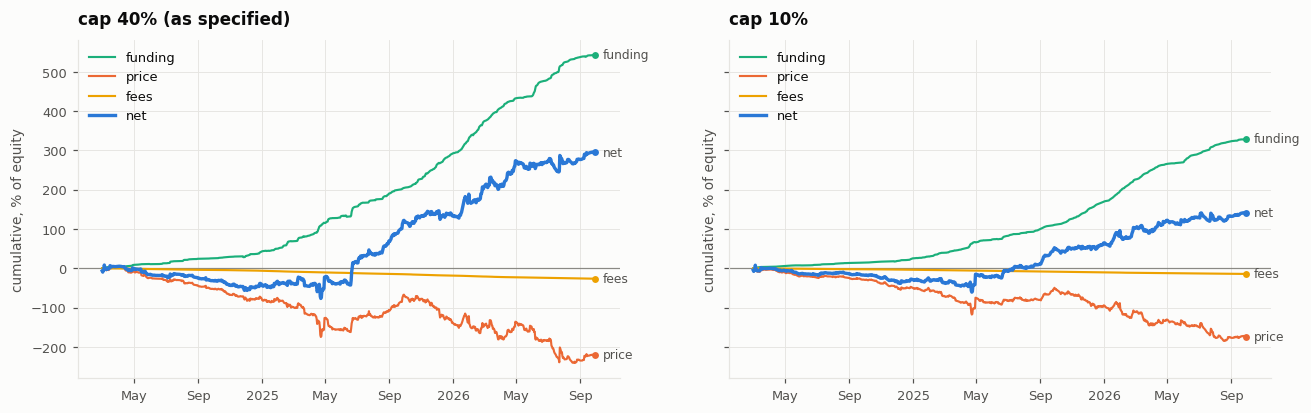

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (k, r) in zip(axes, res.items()):
    pnl_lines(ax, r.daily.rename(columns={"cost": "fee"}), title=k)
save(fig, "attr_components"); plt.show()

## 2. Long leg vs short leg

,avg_gross,avg_coins,funding_apy_%,price_apy_%,net_apy_%,total_%,without_best10_days_%,best_day_%,worst_day_%,book
long,0.6,18.8,214.0,-127.1,86.8,224.6,24.8,38.4,-19.5,cap 40% (as specified)
short,0.4,21.1,-4.1,41.6,37.5,97.1,-17.8,16.6,-21.6,cap 40% (as specified)


,avg_gross,avg_coins,funding_apy_%,price_apy_%,net_apy_%,total_%,without_best10_days_%,best_day_%,worst_day_%,book
long,0.5,19.5,124.6,-78.3,46.3,119.8,-8.3,26.6,-15.5,cap 10%
short,0.3,24.5,2.4,11.1,13.5,35.0,-43.0,13.2,-14.7,cap 10%


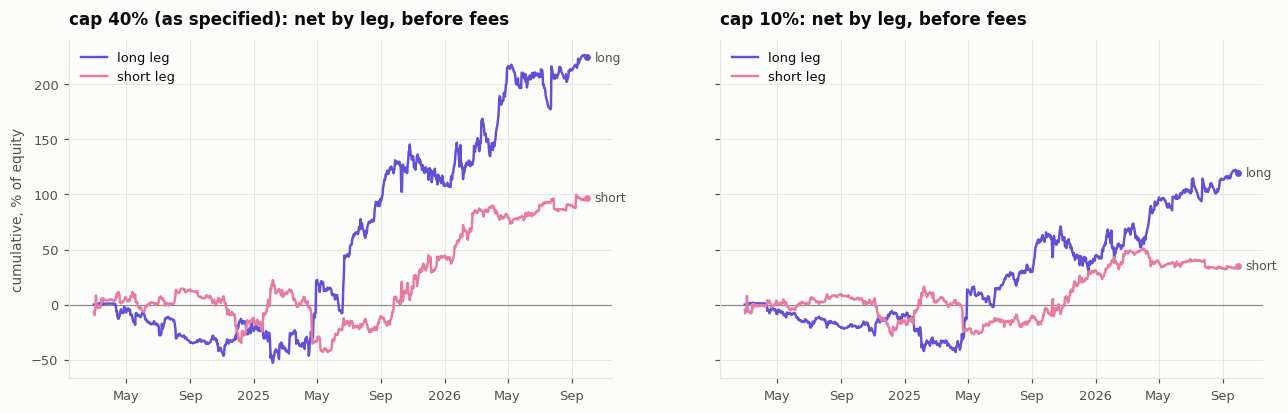

In [4]:
def legs(W, Pr, Fu):
    rows, cum = {}, {}
    for leg, m in [("long", W > 0), ("short", W < 0)]:
        pr, fu = Pr.where(m, 0).sum(axis=1), Fu.where(m, 0).sum(axis=1)
        n = pr + fu; s = n.sort_values()
        rows[leg] = {"avg_gross": W.where(m, 0).abs().sum(axis=1).mean(), "avg_coins": m.sum(axis=1).mean(),
                     "funding_apy_%": fu.mean() * APY, "price_apy_%": pr.mean() * APY, "net_apy_%": n.mean() * APY,
                     "total_%": n.sum() * 100, "without_best10_days_%": s.iloc[:-10].sum() * 100,
                     "best_day_%": n.max() * 100, "worst_day_%": n.min() * 100}
        cum[leg] = n.cumsum() * 100
    return pd.DataFrame(rows).T, pd.DataFrame(cum)
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (k, (W, Pr, Fu)) in zip(axes, P.items()):
    t, c = legs(W, Pr, Fu)
    display(t.round(1).assign(book=k))
    for leg in ("long", "short"):
        ax.plot(c.index, c[leg], color=LEG[leg], label=f"{leg} leg"); end_label(ax, c[leg], leg, LEG[leg])
    zero(ax); ax.set_title(f"{k}: net by leg, before fees"); ax.legend(loc="upper left")
axes[0].set_ylabel("cumulative, % of equity")
save(fig, "attr_legs"); plt.show()

## 3. By size of the funding forecast at entry (AR(1), known at the previous close)

long                              short                        
                       coin_days funding_% price_%  net_% coin_days funding_% price_% net_%
cap 40% (as specified)                                                                     
<25%                        3122       1.5    -3.4   -1.8     13766       8.7    59.6  68.3
25-50%                      3788       3.9   -31.0  -27.0      3544       4.0   -13.5  -9.5
50-100%                     3560      11.0    -7.8    3.1      2009       4.9    -5.3  -0.4
100-300%                    4646      55.3   -35.6   19.7       537       0.5    -7.8  -7.4
>300%                       2673     481.7  -251.1  230.6        80     -28.7    74.7  46.0

long                              short                        
         coin_days funding_% price_%  net_% coin_days funding_% price_% net_%
cap 10%                                                                      
<25%          3258       1.1    -4.2   -3.1     16243       6.5    19.6  26.1
25-50%        3789       3.3   -18.8  -15.5      3970       3.4    -4.1  -0.7
50-100%       3628       9.8   -10.3   -0.6      2220       4.7   -11.3  -6.6
100-300%      5002      51.3   -60.5   -9.2       601       1.5    -0.8   0.7
>300%         2762     256.9  -108.7  148.2        79      -9.8    25.4  15.5

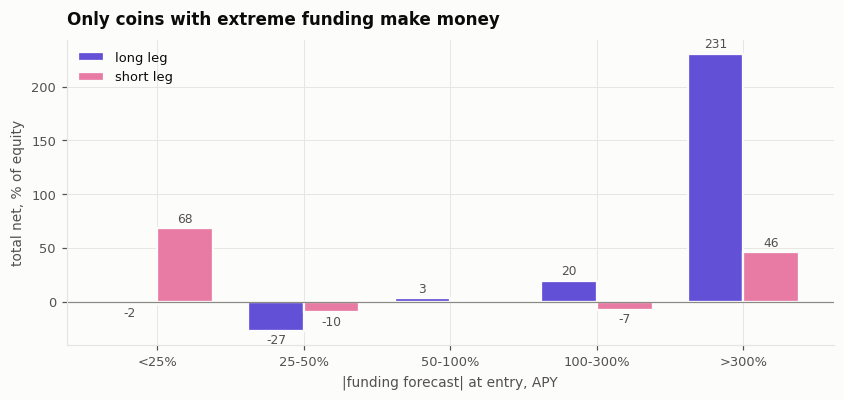

In [5]:
fh = sig.f_hat.shift(1) * APY
edges = [0, 25, 50, 100, 300, np.inf]; labels = ["<25%", "25-50%", "50-100%", "100-300%", ">300%"]
tabs = {}
for k, (W, Pr, Fu) in P.items():
    out = {}
    for leg, m in [("long", W > 0), ("short", W < 0)]:
        x = fh.reindex(index=W.index, columns=W.columns).where(m).abs().stack()
        b = pd.cut(x, edges, labels=labels)
        g = lambda df: df.where(m).stack().reindex(x.index).groupby(b).sum() * 100
        out[(leg, "coin_days")] = b.value_counts().reindex(labels)
        out[(leg, "funding_%")], out[(leg, "price_%")] = g(Fu), g(Pr)
        out[(leg, "net_%")] = out[(leg, "funding_%")] + out[(leg, "price_%")]
    tabs[k] = pd.DataFrame(out); display(tabs[k].round(1).rename_axis(k))
t = tabs[MAIN]
fig, ax = plt.subplots(figsize=(9, 3.6)); xx = np.arange(len(labels)); w = 0.38
for i, leg in enumerate(("long", "short")):
    rr = ax.bar(xx + (i - .5) * w, t[(leg, "net_%")], w, color=LEG[leg], edgecolor=SURFACE, lw=1.5, label=f"{leg} leg")
    ax.bar_label(rr, labels=[f"{v:.0f}" if abs(v) >= 0.5 else "" for v in t[(leg, "net_%")].fillna(0)],
                 fontsize=8, color=INK2, padding=2)
zero(ax); ax.set_xticks(xx, labels); ax.set_xlabel("|funding forecast| at entry, APY")
ax.set_ylabel("total net, % of equity"); ax.set_title("Only coins with extreme funding make money"); ax.legend()
save(fig, "attr_buckets"); plt.show()

## 4. By liquidity of the coin (trailing 30-day mean daily volume, known at entry)

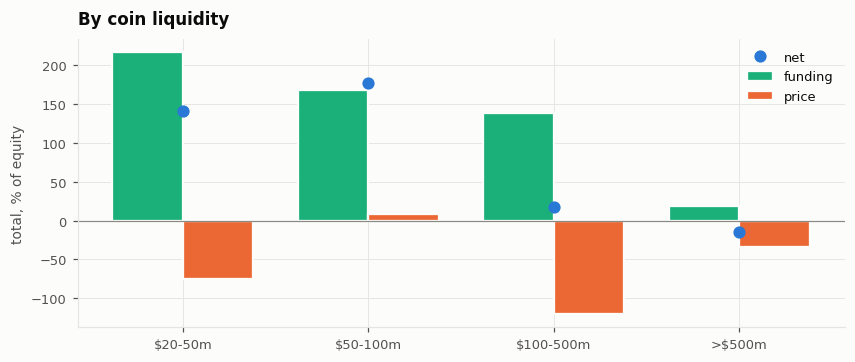

,coin_days,funding_%,price_%,net_%
$20-50m,18124,216.9,-75.0,141.8
$50-100m,8956,168.7,8.8,177.5
$100-500m,9276,138.2,-120.7,17.5
>$500m,1369,19.0,-34.2,-15.2


In [6]:
dv = sig.dv7.shift(1)
lb = [0, 5e7, 1e8, 5e8, np.inf]; ll = ["$20-50m", "$50-100m", "$100-500m", ">$500m"]   # floor is $20m
W, Pr, Fu = P[MAIN]
x = dv.reindex(index=W.index, columns=W.columns).where(W != 0).stack()
b = pd.cut(x, lb, labels=ll)
g = lambda df: df.stack().reindex(x.index).groupby(b).sum()
liq = pd.DataFrame({"coin_days": b.value_counts().reindex(ll), "funding_%": g(Fu) * 100, "price_%": g(Pr) * 100})
liq["net_%"] = liq["funding_%"] + liq["price_%"]
fig, ax = plt.subplots(figsize=(9, 3.4)); xx = np.arange(len(ll)); w = 0.38
for i, c in enumerate(("funding", "price")):
    ax.bar(xx + (i - .5) * w, liq[f"{c}_%"], w, color=PNL[c], edgecolor=SURFACE, lw=1.5, label=c)
ax.plot(xx, liq["net_%"], "o", color=PNL["net"], ms=7, label="net")
zero(ax); ax.set_xticks(xx, ll); ax.set_ylabel("total, % of equity"); ax.set_title("By coin liquidity"); ax.legend()
save(fig, "attr_liquidity"); plt.show()
liq.round(1)

## 5. Concentration: best days and best coins

cap 40% (as specified): total 295% | without best 1/3/5/10/20 days: 255%, 203%, 166%, 97%, -19%
cap 10%: total 140% | without best 1/3/5/10/20 days: 114%, 83%, 57%, 10%, -50%


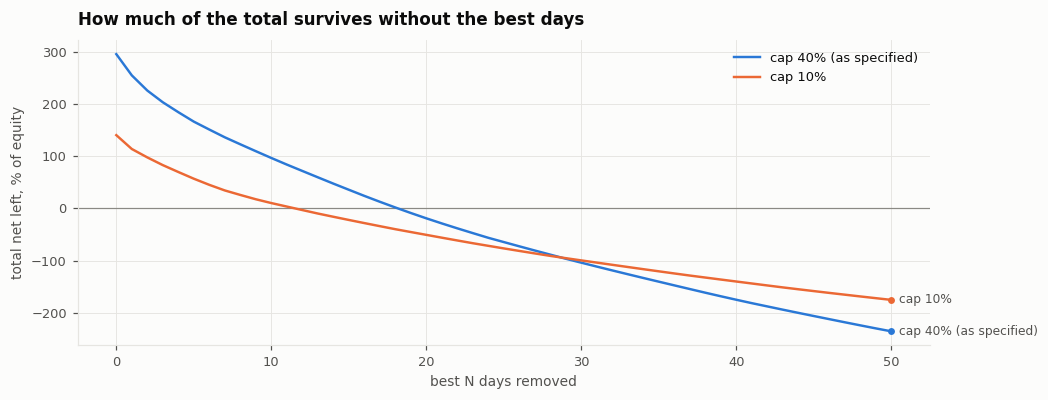

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for (k, r), c in zip(res.items(), SERIES):
    n = r.daily["net"].sort_values(ascending=False)
    left = pd.Series([n.iloc[i:].sum() * 100 for i in range(0, 51)])
    ax.plot(left.index, left, color=c, label=k); end_label(ax, left, k, c)
    print(f"{k}: total {n.sum()*100:.0f}% | without best 1/3/5/10/20 days: " +
          ", ".join(f"{n.iloc[i:].sum()*100:.0f}%" for i in (1, 3, 5, 10, 20)))
zero(ax); ax.set_xlabel("best N days removed"); ax.set_ylabel("total net left, % of equity")
ax.set_title("How much of the total survives without the best days"); ax.legend(loc="upper right")
save(fig, "attr_concentration"); plt.show()

In [8]:
W, Pr, Fu = P[MAIN]; d = res[MAIN].daily
top = d["net"].sort_values(ascending=False).index[:8].append(d["net"].sort_values().index[:5])
rows = []
for day in top:
    c = (Pr.loc[day] + Fu.loc[day]).abs().idxmax()
    rows.append({"date": day.date(), "net_%": d.loc[day, "net"] * 100, "driver": c, "weight": W.loc[day, c],
                 "coin_return_%": panel.ret.loc[day, c] * 100, "coin_funding_%/day": panel.funding.loc[day, c] * 100,
                 "coin_volume_$m": panel.dollar_volume.loc[day, c] / 1e6})
print("best 8 and worst 5 days:"); pd.DataFrame(rows).round(2)

best 8 and worst 5 days:


,date,net_%,driver,weight,coin_return_%,coin_funding_%/day,coin_volume_$m
0,2026-07-24,40.59,DEXE,0.22,159.54,-7.62,1146.81
1,2025-04-30,29.02,ALPACA,0.06,520.21,15.39,3110.19
2,2025-06-21,22.40,FUN,0.39,32.11,-18.84,2353.30
3,2026-03-12,18.97,LYN,0.40,50.54,-3.39,401.59
4,2025-04-25,18.06,ALPACA,0.08,163.30,-29.17,3160.46
5,2026-01-31,15.15,SENT,0.23,33.55,-9.00,654.27
6,2026-05-28,14.83,GUA,0.11,119.48,0.93,410.45
7,2024-03-05,13.36,LTC,-0.13,-7.94,0.25,959.84
8,2025-04-22,-20.75,ZEREBRO,-0.16,109.53,0.16,572.67
9,2026-02-01,-17.41,BULLA,0.11,-93.03,-3.30,249.93


## 6. Price P&L: market part vs coin-specific residual

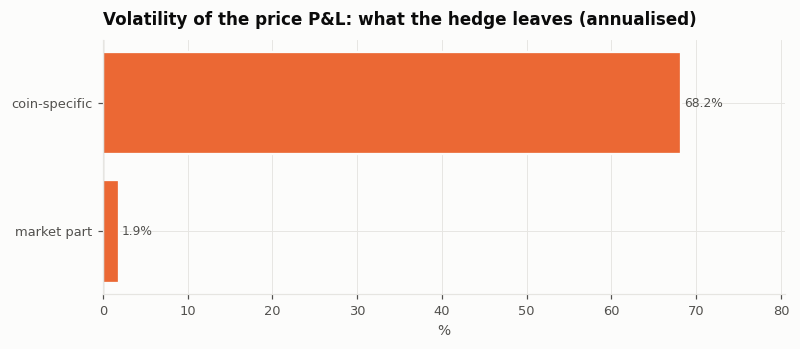

,price_apy_%,market_part_apy_%,residual_apy_%,market_part_vol_%,residual_vol_%
cap 40% (as specified),-85.53,0.95,-86.48,1.90,68.19
cap 10%,-67.23,0.67,-67.90,1.91,43.69


In [9]:
_, _, exp = market_betas(panel.ret, cfg["beta"]["type"], cfg["beta"]["window_days"], cfg["beta"]["min_days"])
fd = {"BTC": panel.ret["BTC"], "ETH": panel.ret["ETH"], "MKT": (panel.ret["BTC"] + panel.ret["ETH"]) / 2}
rows = {}
for k, (W, Pr, Fu) in P.items():
    mkt = sum((W * exp[f].shift(1).reindex(index=W.index, columns=W.columns).fillna(0)).mul(fd[f].reindex(W.index), axis=0) for f in exp)
    rows[k] = {"price_apy_%": Pr.sum(axis=1).mean() * APY, "market_part_apy_%": mkt.sum(axis=1).mean() * APY,
               "residual_apy_%": (Pr - mkt).sum(axis=1).mean() * APY,
               "market_part_vol_%": mkt.sum(axis=1).std() * np.sqrt(365) * 100,
               "residual_vol_%": (Pr - mkt).sum(axis=1).std() * np.sqrt(365) * 100}
mr = pd.DataFrame(rows).T
fig, ax = plt.subplots(figsize=(8, 3))
bars(ax, mr.loc[MAIN, ["market_part_vol_%", "residual_vol_%"]].rename({"market_part_vol_%": "market part", "residual_vol_%": "coin-specific"}),
     color=PNL["price"], horizontal=True, fmt="{:.1f}%")
ax.set_title("Volatility of the price P&L: what the hedge leaves (annualised)"); ax.set_xlabel("%")
save(fig, "attr_market_residual"); plt.show()
mr.round(2)

## 7. By quarter

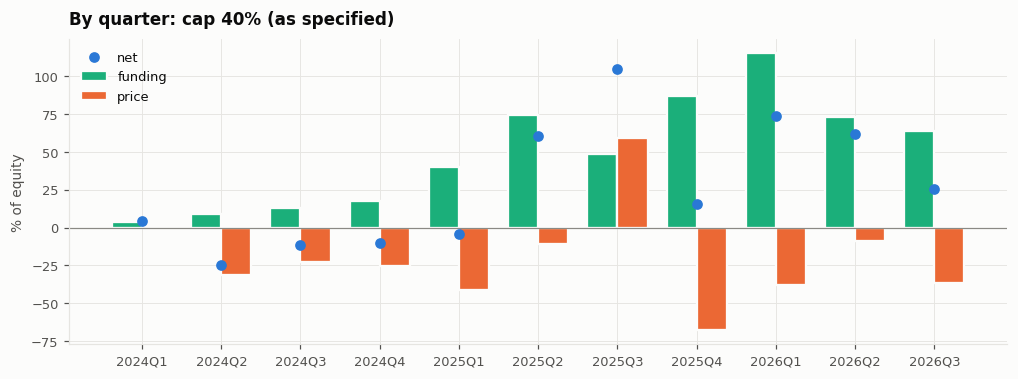

date,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
funding,3.8,8.9,12.5,17.6,40.0,73.9,48.4,86.9,114.9,72.6,63.4
price,1.1,-31.3,-22.5,-25.2,-40.9,-10.9,59.1,-67.8,-37.9,-8.6,-36.2
cost,0.4,2.2,1.7,2.2,3.2,3.0,2.7,3.5,3.5,2.2,2.0
net,4.5,-24.6,-11.6,-9.9,-4.1,60.0,104.7,15.7,73.5,61.8,25.1


In [10]:
r = res[MAIN].daily
q = r[["funding", "price", "cost", "net"]].groupby(r.index.to_period("Q")).sum().mul(100)
fig, ax = plt.subplots(figsize=(11, 3.6)); xx = np.arange(len(q)); w = 0.38
ax.bar(xx - w/2, q["funding"], w, color=PNL["funding"], edgecolor=SURFACE, lw=1.5, label="funding")
ax.bar(xx + w/2, q["price"], w, color=PNL["price"], edgecolor=SURFACE, lw=1.5, label="price")
ax.plot(xx, q["net"], "o", color=PNL["net"], ms=6, label="net")
zero(ax); ax.set_xticks(xx, [str(p) for p in q.index]); ax.set_ylabel("% of equity"); ax.set_title(f"By quarter: {MAIN}"); ax.legend(loc="upper left")
save(fig, "attr_quarterly"); plt.show()
q.round(1).T

## Findings

- **The hedge works; the risk left is coin-specific.** The market part of price P&L moves 1.9% a year; the coin-specific part 68%.
- **Funding is real, price eats most of it**: +210% APY funding, −86% price, −10% fees → +114% APY net, Sharpe 1.62 (as specified, $20m floor).
- **The long leg earns, mostly at the extreme.** Longs entered at |forecast| > 300% APY make +231% of the total; the 25–100% buckets lose. Shorts at low funding (< 25%) make +68% - on price, not carry.
- **Liquidity**: almost all of it from $20–100m/day coins (+319%); coins above $100m/day net ≈ +2%.
- **Concentration**: 295% total; without the best 10 days 97%, without the best 20 −19%.
- **Time**: 2024 loses in three of four quarters; the profit is 2025–26.